In [1]:
import sympy as sp
import numpy as np
from scipy.optimize import minimize_scalar, minimize
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.integrate import solve_ivp, odeint

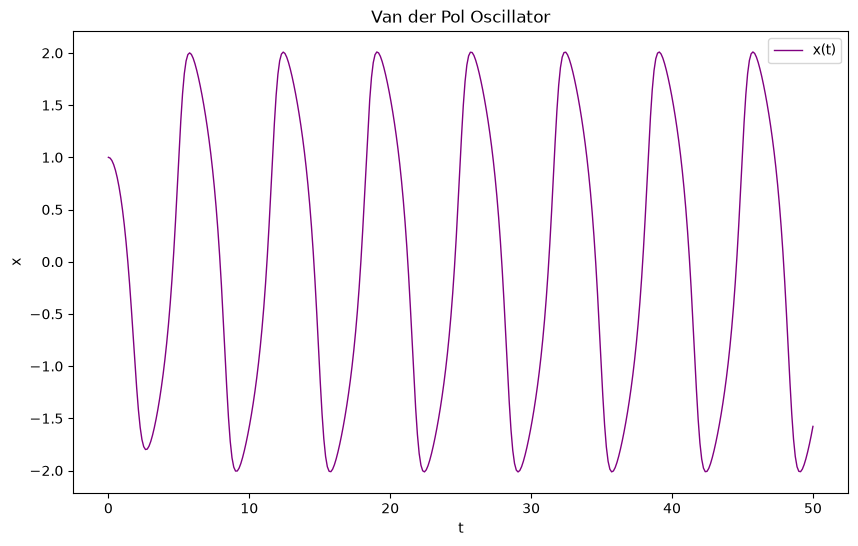

   rtol      max error   calls of f
   1e-03     2.2e-02    1106
   1e-06     2.7e-02    1106
   1e-09     2.7e-02    1106


In [ ]:
# Two-Dimensional system: Van der Pol oscillator
tt=np.linspace(0,50,400)
u=1.0
def f(t, xy):
    x,y=xy
    return [y, u*(1-x**2)*y-x]

def y_exact(t):
    return np.exp(-t/2) * np.cos(t)

sol = solve_ivp(f,(0,50),[1,0], t_eval=tt)

fig,ax=plt.subplots(figsize=(10,6))

ax.plot(sol.t, sol.y[0], color='purple', lw=1, label='x(t)')

ax.set_xlabel('t')
ax.set_ylabel('x')
ax.set_title('Van der Pol Oscillator')
ax.legend()

plt.show()

print("   rtol      max error   calls of f")
for rtol in [1e-3, 1e-6, 1e-9]:
    sol_exact = solve_ivp(f, (0, 50), [1,0], t_eval=tt, rtol=rtol, atol=1e-12)
    err = np.max(np.abs(sol.y[0] - sol_exact.y[0]))
    print(f"{rtol:8.0e}   {err:9.1e}   {sol.nfev:5d}")

#Check accuracy of solver on an equation with a known exact solution, such as:
# f'=f(1-f) from [1]. Plot error at a fixed final time against the tolerance
# rtol on a log-log scale.



#Discuss how the tolerance affects the accuracy

# Compare different methods offered by solve_ivp, such as RK45, DOP853, and Radau
# in accuracy and computing time.


In [ ]:
# Three-Dimensional system: Lorenz system
#Write the first-order ODEs
tt = np.linspace(0,50,400)
def f(t, xyz):
    x,y,z=xyz 
    return [s*(y-x),x*(p-z)-y,x*y-b*z]

def y_exact(t):
    return 1 - np.exp(-t)

s=10.0 ; p=28.0 ; b=8.0/3.0
sol=solve_ivp(f,(0,50), [.01,.01,.01],t_eval=tt)

fig,ax=plt.subplots(figsize=(10,6))
plt.axhline(x2, color='black',lw=1,linestyle='--',label=f"Steady state: x={x2:.2f}")
plt.axhline(-x2, color='black',lw=1,linestyle='--',label=f"Steady state: x={-x2:.2f}")

ax.plot(sol.t,sol.y[0],'-',color='purple',lw=1,label='Trajectory')

ax.set_xlabel('t'); ax.set_ylabel('x'); ax.set_title('Lorenz System')
ax.legend()
plt.show()

print("   rtol      max error   calls of f")
for rtol in [1e-3, 1e-6, 1e-9]:
    sol = solve_ivp(f, (0, 50), [.01,.01,.01], t_eval=tt, rtol=rtol, atol=1e-12)
    err = np.max(np.abs(sol.y[0] - y_exact(tt)))
    print(f"{rtol:8.0e}   {err:9.1e}   {sol.nfev:5d}")


# When |y| is large, rtol controls the accuracy; when |y| is small, atol does. 
# Smaller tolerances results in smaller errors.
